# Exercises XP — SciPy and statistics

Octopus Week 2 · Day 3

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1706/chapter/4344)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Exercise 1 — SciPy version

In [2]:
import scipy
from scipy import stats
print('SciPy',scipy.__version__)

SciPy 1.18.1


## Exercise 2 — Descriptive statistics
Report population and sample variance explicitly. SciPy describe defaults to sample variance (ddof=1); NumPy supplies mean/median and the matching standard deviation.

In [3]:
data=np.array([12,15,13,12,18,20,22,21])
desc=stats.describe(data,ddof=1)
display(pd.Series({'mean':desc.mean,'median':np.median(data),'sample variance':desc.variance,'sample std':np.sqrt(desc.variance),'population variance':np.var(data,ddof=0),'population std':np.std(data,ddof=0)}))
assert np.isclose(desc.mean,16.625)

mean                   16.625000
median                 16.500000
sample variance        17.125000
sample std              4.138236
population variance    14.984375
population std          3.870966
dtype: float64

## Exercise 3 — Normal distribution (mean 50, standard deviation 10)

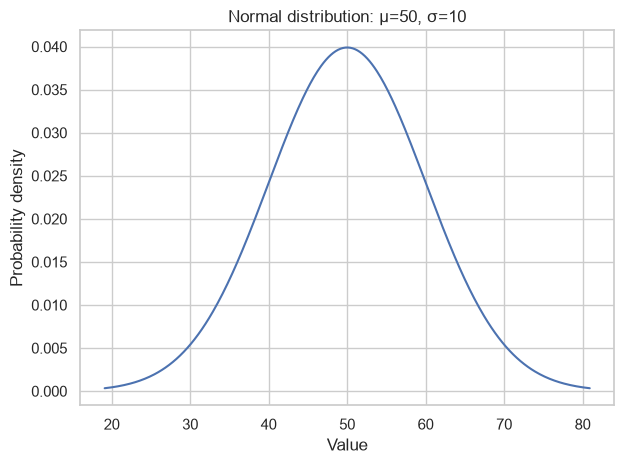

In [4]:
distribution=stats.norm(loc=50,scale=10)
x=np.linspace(distribution.ppf(.001),distribution.ppf(.999),400)
plt.plot(x,distribution.pdf(x));plt.title('Normal distribution: μ=50, σ=10');plt.xlabel('Value');plt.ylabel('Probability density')
savefig('day3_normal_distribution')

## Exercise 4 — Independent two-sample t test
Use a fixed seed for reproducibility and Welch’s test to avoid requiring equal variances. Null hypothesis: population means are equal; two-sided α=0.05.

In [5]:
rng=np.random.default_rng(42)
data1=rng.normal(50,10,100);data2=rng.normal(60,10,100)
test=stats.ttest_ind(data1,data2,equal_var=False)
print('t:',test.statistic,'p:',test.pvalue)
print('Reject equal means' if test.pvalue<.05 else 'Do not reject equal means')
print('The simulated samples were generated with different means; this does not establish effects in real populations.')

t: -8.316637727945363 p: 1.7862759561634344e-14
Reject equal means
The simulated samples were generated with different means; this does not establish effects in real populations.


## Exercise 5 — House-size linear regression

Slope: 1,828.77; intercept: 64,383.56; predicted price at 90 m²: 228,972.60
Each additional square metre is associated with 1,828.77 currency units in predicted price within this small dataset.


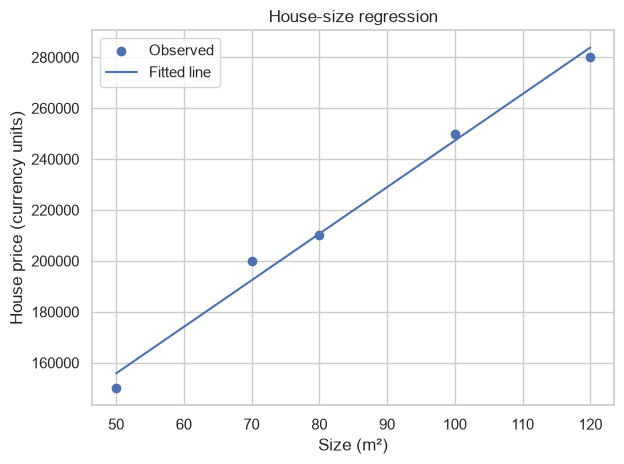

In [6]:
house_sizes=np.array([50,70,80,100,120])
house_prices=np.array([150000,200000,210000,250000,280000])
reg=stats.linregress(house_sizes,house_prices)
prediction=reg.intercept+reg.slope*90
print(f'Slope: {reg.slope:,.2f}; intercept: {reg.intercept:,.2f}; predicted price at 90 m²: {prediction:,.2f}')
print(f'Each additional square metre is associated with {reg.slope:,.2f} currency units in predicted price within this small dataset.')
plt.scatter(house_sizes,house_prices,label='Observed');plt.plot(house_sizes,reg.intercept+reg.slope*house_sizes,label='Fitted line')
plt.xlabel('Size (m²)');plt.ylabel('House price (currency units)');plt.title('House-size regression');plt.legend()
savefig('day3_house_regression')

## Exercise 6 — One-way ANOVA
H₀: all three fertilizer population means are equal. Assume independent observations, approximately normal errors and similar variances; the five-observation groups are too small to validate those assumptions strongly.

In [7]:
fertilizer_1=[5,6,7,6,5];fertilizer_2=[7,8,7,9,8];fertilizer_3=[4,5,4,3,4]
a=stats.f_oneway(fertilizer_1,fertilizer_2,fertilizer_3)
print('F:',a.statistic,'p:',a.pvalue)
print('Reject equality of group means' if a.pvalue<.05 else 'Do not reject equality')
print('A significant omnibus test indicates at least one mean differs; it does not identify every differing pair. If p > .05, fail to reject H0; do not conclude that effects are identical.')

F: 28.52631578947368 p: 2.7542672098048448e-05
Reject equality of group means
A significant omnibus test indicates at least one mean differs; it does not identify every differing pair. If p > .05, fail to reject H0; do not conclude that effects are identical.


## Exercise 7 — Binomial distribution (included optional question)

In [8]:
prob=stats.binom.pmf(5,n=10,p=.5)
print('P(exactly 5 heads in 10 fair, independent flips):',prob)
assert np.isclose(prob,252/1024)

P(exactly 5 heads in 10 fair, independent flips): 0.2460937500000002


## Exercise 8 — Pearson and Spearman correlation (included optional question)

In [9]:
data=pd.DataFrame({'age':[23,25,30,35,40],'income':[35000,40000,50000,60000,70000]})
print('Pearson:',stats.pearsonr(data['age'],data['income']))
print('Spearman:',stats.spearmanr(data['age'],data['income']))
print('Both show positive association. Spearman tests monotonic ranking, Pearson linear association; neither establishes causality.')

Pearson: PearsonRResult(statistic=np.float64(0.9996907452347201), pvalue=np.float64(6.528122732016004e-06))
Spearman: SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(1.4042654220543602e-24))
Both show positive association. Spearman tests monotonic ranking, Pearson linear association; neither establishes causality.
